# Hands-on: Konsep Landmark & Pembacaan Koordinat (MediaPipe)

### Study group IMV Laboratory.

**Alur Pembelajaran:**
1. Akuisisi citra & setup MediaPipe
2. Konsep landmark tangan (21 titik) & tubuh (33 titik)
3. Sistem koordinat ternormalisasi $(x, y, z)$
4. Konversi ke piksel layar $(cx, cy)$
5. Isolasi landmark spesifik untuk Virtual Painter & Volume Control
6. Latihan praktikan

**Library:** `opencv-python`, `mediapipe`, `numpy`, `matplotlib`

```bash
pip install opencv-python mediapipe numpy matplotlib
```

In [6]:
import os
import math
import numpy as np
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

mp_hands = mp.solutions.hands
mp_draw = mp.solutions.drawing_utils
plt.rcParams['figure.dpi'] = 100

## 0. Persiapan: Fungsi Bantu & Akuisisi Citra Tangan

- OpenCV membaca gambar dalam **BGR**, sedangkan MediaPipe & Matplotlib bekerja di **RGB**. Konversi `cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)` **wajib** sebelum `hands.process(frame_rgb)` dan sebelum `plt.imshow`. Jika terlewat: deteksi gagal dan warna tampil tertukar (merah tampak biru).

**Urutan input (dicek berurutan, otomatis):**
1. **Colab / upload** atau **file lokal** bernama `hand.jpg` (alternatif: `image.jpg`) → dibaca dengan `cv2.imread`.
2. **Webcam** → ambil 1 frame via `cv2.VideoCapture(0)`.
3. **Fallback otomatis** → jika keduanya gagal (file tidak ada, gambar kosong, tidak ada kamera), dibuat kanvas sintetis `(480, 640, 3)` berisi siluet telapak tangan.

**Fallback landmark:** jika `results.multi_hand_landmarks is None` (tidak ada tangan terdeteksi), notebook memakai **21 koordinat landmark sintetis** berbentuk telapak terbuka. Variabel `hand_lms` karena itu **selalu terisi** → sel-sel berikutnya bebas dari error `NoneType`.

Sumber citra : webcam (1 frame) | landmark asli MediaPipe
Jumlah titik : 21 | shape (h, w, c) = (480, 640, 3)


c:\Users\Zepunnn\hands-env\lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


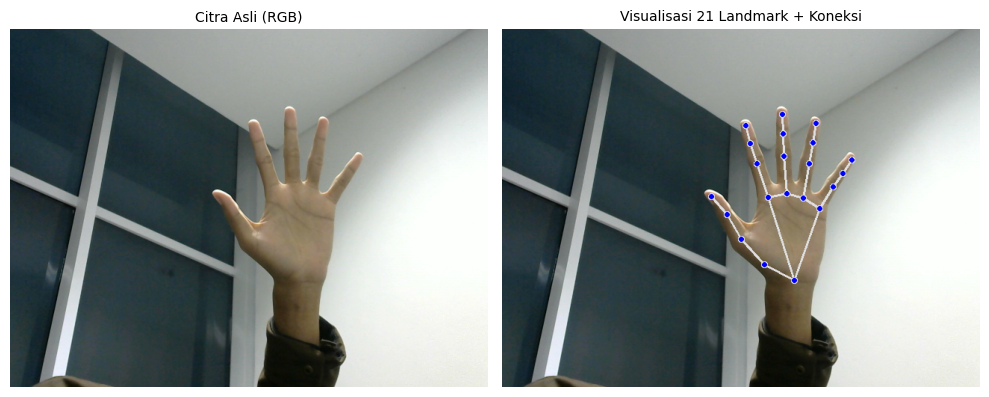

In [7]:
def show(images, titles, cols=3, size=(4, 4)):
    rows = math.ceil(len(images) / cols)
    plt.figure(figsize=(size[0] * cols, size[1] * rows))
    for i, (im, title) in enumerate(zip(images, titles)):
        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(im, cmap='gray' if im.ndim == 2 else None)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


# --- Fallback: 21 landmark sintetis (telapak tangan terbuka) dalam koordinat ternormalisasi ---
SYNTH_LMS = [
    (0.50, 0.92, 0.00),                                    # 0  wrist
    (0.42, 0.85, -0.01), (0.34, 0.78, -0.02),              # 1-2 thumb
    (0.28, 0.72, -0.03), (0.23, 0.66, -0.04),              # 3-4 thumb tip
    (0.40, 0.60, 0.00), (0.38, 0.45, -0.01),               # 5-6 index
    (0.37, 0.35, -0.02), (0.36, 0.26, -0.03),              # 7-8 index tip
    (0.50, 0.58, 0.00), (0.50, 0.40, -0.01),               # 9-10 middle
    (0.50, 0.29, -0.02), (0.50, 0.19, -0.03),              # 11-12 middle tip
    (0.60, 0.60, 0.00), (0.62, 0.43, -0.01),               # 13-14 ring
    (0.63, 0.32, -0.02), (0.64, 0.23, -0.03),              # 15-16 ring tip
    (0.69, 0.65, 0.00), (0.73, 0.52, -0.01),               # 17-18 pinky
    (0.75, 0.43, -0.02), (0.77, 0.36, -0.03),              # 19-20 pinky tip
]


class LM:
    def __init__(self, x, y, z):
        self.x, self.y, self.z = x, y, z


def make_synthetic_hand(h=480, w=640):
    canvas = np.full((h, w, 3), 235, np.uint8)
    pts = [(int(x * w), int(y * h)) for x, y, _ in SYNTH_LMS]
    skin = (150, 180, 215)                                 # BGR
    cv2.fillPoly(canvas, [np.array([pts[i] for i in (0, 1, 5, 9, 13, 17)])], skin, cv2.LINE_AA)
    for chain in ((1, 2, 3, 4), (5, 6, 7, 8), (9, 10, 11, 12), (13, 14, 15, 16), (17, 18, 19, 20)):
        cv2.polylines(canvas, [np.array([pts[i] for i in chain])], False, skin, 26, cv2.LINE_AA)
    return cv2.GaussianBlur(canvas, (9, 9), 0)


def load_frame():
    for name in ('hand.jpg', 'image.jpg'):
        if os.path.exists(name):
            img = cv2.imread(name)
            if img is not None:
                return img, f'file lokal: {name}'
    cap = cv2.VideoCapture(0)
    if cap.isOpened():
        ok, frame = cap.read()
        cap.release()
        if ok and frame is not None:
            return frame, 'webcam (1 frame)'
    return make_synthetic_hand(), 'kanvas sintetis 480x640'


frame_bgr, source = load_frame()
frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)      # wajib: BGR -> RGB
h, w, c = frame_rgb.shape

hands = mp_hands.Hands(static_image_mode=True, max_num_hands=1, min_detection_confidence=0.5)
results = hands.process(frame_rgb)

if results.multi_hand_landmarks:
    hand_lms = list(results.multi_hand_landmarks[0].landmark)
    source += ' | landmark asli MediaPipe'
else:
    hand_lms = [LM(x, y, z) for x, y, z in SYNTH_LMS]
    source += ' | FALLBACK landmark sintetis'

annotated = frame_rgb.copy()
if results.multi_hand_landmarks:
    mp_draw.draw_landmarks(annotated, results.multi_hand_landmarks[0], mp_hands.HAND_CONNECTIONS)
else:
    pts = [(int(lm.x * w), int(lm.y * h)) for lm in hand_lms]
    for a, b in mp_hands.HAND_CONNECTIONS:
        cv2.line(annotated, pts[a], pts[b], (0, 200, 255), 2, cv2.LINE_AA)
    for p in pts:
        cv2.circle(annotated, p, 4, (255, 0, 0), -1, cv2.LINE_AA)

print('Sumber citra :', source)
print('Jumlah titik :', len(hand_lms), '| shape (h, w, c) =', (h, w, c))
show([frame_rgb, annotated], ['Citra Asli (RGB)', 'Visualisasi 21 Landmark + Koneksi'], cols=2, size=(5, 4))

## 1. Konsep Landmark & Sistem Koordinat (x, y, z)

**Dua model landmark MediaPipe:**
- **Hand Landmarks — 21 titik (indeks 0-20):** 1 pergelangan + 4 titik × 5 jari. Dipakai pada Virtual Painter & Volume Control.
- **Pose Landmarks — 33 titik (indeks 0-32):** kerangka tubuh penuh (hidung, mata, telinga, bahu, siku, pergelangan, pinggul, lutut, mata kaki). Dipakai untuk analisis postur.

**Indeks kunci tangan yang wajib dihafal:**
- `0` = Wrist (pergelangan) → titik acuan kedalaman `z`
- `4` = Thumb Tip (ujung jempol) → Volume Control
- `8` = Index Tip (ujung telunjuk) → kursor Virtual Painter
- `12` = Middle Tip, `16` = Ring Tip, `20` = Pinky Tip → finger counter

**Normalized Coordinates (MediaPipe):**
- `x` = horizontal, `0.0` (tepi kiri) → `1.0` (tepi kanan)
- `y` = vertikal, `0.0` (tepi atas) → `1.0` (tepi bawah). Perhatikan: makin ke bawah posisinya, makin **besar** nilai `y`
- `z` = kedalaman relatif terhadap pergelangan; makin **negatif** berarti makin dekat ke kamera
- Ketiganya rasio float terhadap ukuran frame — **bukan** piksel.

ID  0 | x = 0.6121  y = 0.7041  z = +0.0000
ID  4 | x = 0.4385  y = 0.4694  z = -0.0701
ID  8 | x = 0.5097  y = 0.2717  z = -0.0697
ID 12 | x = 0.5875  y = 0.2408  z = -0.0648
ID 16 | x = 0.6567  y = 0.2651  z = -0.0733
ID 20 | x = 0.7321  y = 0.3672  z = -0.0742


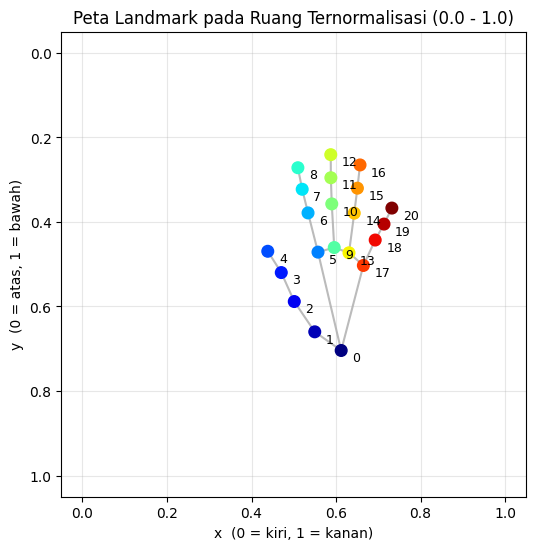

In [8]:
for idx in (0, 4, 8, 12, 16, 20):
    lm = hand_lms[idx]
    print(f'ID {idx:>2} | x = {lm.x:.4f}  y = {lm.y:.4f}  z = {lm.z:+.4f}')

xs = [lm.x for lm in hand_lms]
ys = [lm.y for lm in hand_lms]

plt.figure(figsize=(6, 7))
for a, b in mp_hands.HAND_CONNECTIONS:
    plt.plot([xs[a], xs[b]], [ys[a], ys[b]], color='#bbbbbb', lw=1.5, zorder=1)
plt.scatter(xs, ys, c=range(len(xs)), cmap='jet', s=70, zorder=2)
for i, (x, y) in enumerate(zip(xs, ys)):
    plt.annotate(str(i), (x, y), xytext=(8, -8), textcoords='offset points', fontsize=9)
plt.xlim(-0.05, 1.05)
plt.ylim(1.05, -0.05)                                       # sumbu y dibalik: 0 di atas
plt.gca().set_aspect('equal')
plt.grid(alpha=0.3)
plt.title('Peta Landmark pada Ruang Ternormalisasi (0.0 - 1.0)')
plt.xlabel('x  (0 = kiri, 1 = kanan)')
plt.ylabel('y  (0 = atas, 1 = bawah)')
plt.show()

## 2. Konversi Koordinat ke Piksel Layar (cx, cy)

- Nilai `lm.x` / `lm.y` bertipe float `0.0 - 1.0`, sedangkan `cv2.circle`, `cv2.line`, dan `cv2.putText` hanya menerima **koordinat integer piksel**. Tanpa konversi, titik tergambar di posisi salah (sering menumpuk di pojok kiri atas).

**Rumus konversi:**
- `cx = int(lm.x × w)`  → kolom piksel
- `cy = int(lm.y × h)`  → baris piksel
- Dimensi diambil dengan `h, w, c = frame.shape` (urutan OpenCV: tinggi, lebar, channel — **bukan** lebar dulu).

**Iterasi seluruh titik:**
- `for idx, lm in enumerate(hand_lms):` → `idx` = ID landmark (0-20), `lm` = objek dengan atribut `.x`, `.y`, `.z`.
- Simpan hasilnya ke struktur `lm_list = [[id, cx, cy], ...]` agar mudah difilter per-ID di tahap berikutnya.

5 titik pertama [id, cx, cy]:
   [0, 391, 337]
   [1, 351, 316]
   [2, 320, 282]
   [3, 301, 249]
   [4, 280, 225]


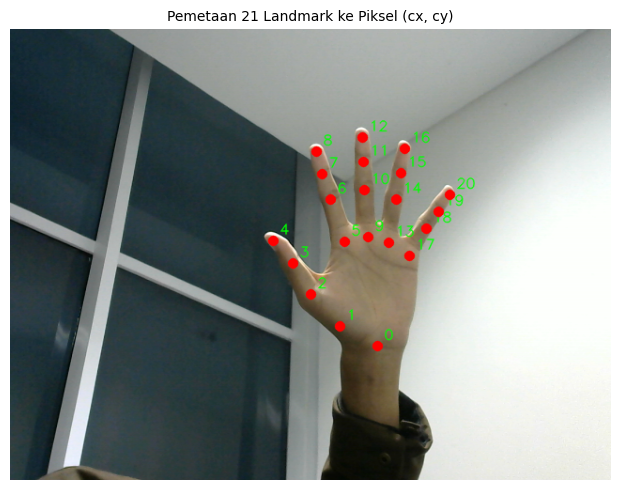

In [9]:
lm_list = []
for idx, lm in enumerate(hand_lms):
    cx, cy = int(lm.x * w), int(lm.y * h)
    lm_list.append([idx, cx, cy])

print('5 titik pertama [id, cx, cy]:')
for row in lm_list[:5]:
    print('  ', row)

canvas_ids = frame_rgb.copy()
for idx, cx, cy in lm_list:
    cv2.circle(canvas_ids, (cx, cy), 5, (255, 0, 0), -1, cv2.LINE_AA)
    cv2.putText(canvas_ids, str(idx), (cx + 7, cy - 7), cv2.FONT_HERSHEY_SIMPLEX,
                0.5, (0, 255, 0), 1, cv2.LINE_AA)

show([canvas_ids], ['Pemetaan 21 Landmark ke Piksel (cx, cy)'], cols=1, size=(8, 5))

## 3. Isolasi Landmark Spesifik untuk Proyek (Virtual Painter & Volume Control)

Setelah `lm_list` jadi, kita tidak perlu semua 21 titik — cukup **filter ID tertentu**.

**1. Virtual Painter (kursor kuas)**
- Kursor = posisi `(cx, cy)` dari **ID 8** (ujung telunjuk).
- Status menggambar dicek dengan membandingkan tinggi jari: telunjuk dianggap **terangkat** jika `cy` ujung jari (ID 8) **<** `cy` sendi tengahnya (ID 6). Ingat: `cy` kecil = posisi lebih tinggi di layar.

**2. Volume Control (jarak cubitan)**
- Ambil **ID 4** (ujung jempol) dan **ID 8** (ujung telunjuk).
- Gambar garis penghubung + titik tengah `((x1+x2)/2, (y1+y2)/2)` sebagai indikator cubitan.
- Hitung jarak Euclidean dalam piksel: `math.hypot(x2 - x1, y2 - y1)` → makin lebar cubitan, makin besar nilainya (nanti dipetakan ke level volume).

ID 4 (jempol)   -> (cx, cy) = (280, 225)
ID 8 (telunjuk) -> (cx, cy) = (326, 130)
Jarak Euclidean ID 4 - ID 8 = 105.55 px
Telunjuk terangkat? True


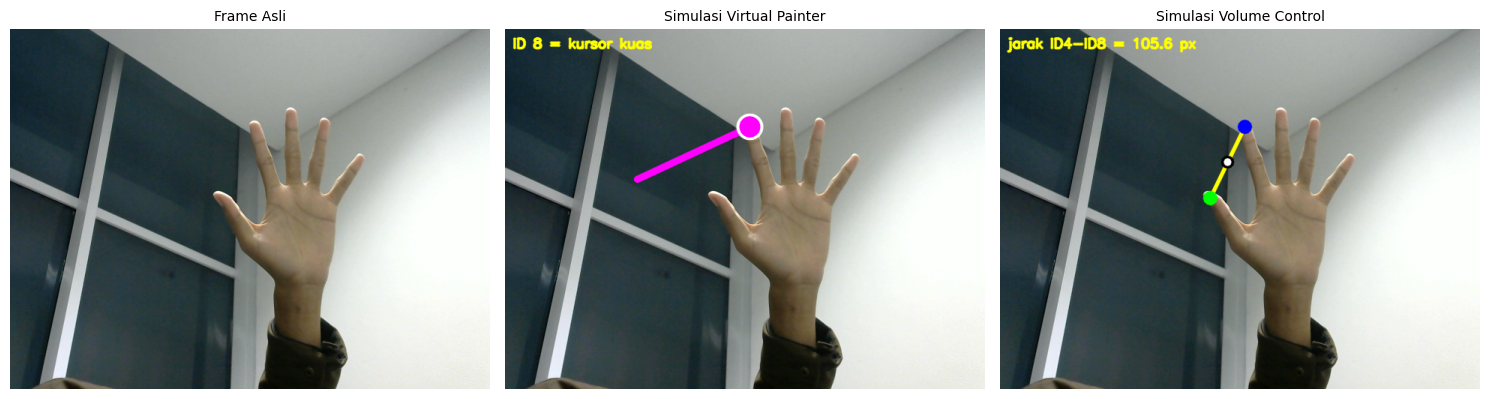

In [10]:
base = frame_rgb.copy()

# --- 1) Simulasi Virtual Painter: ID 8 sebagai kursor kuas ---
painter = base.copy()
p8 = (lm_list[8][1], lm_list[8][2])
cv2.line(painter, (p8[0] - 150, p8[1] + 70), p8, (255, 0, 255), 8, cv2.LINE_AA)   # simulasi goresan
cv2.circle(painter, p8, 16, (255, 0, 255), -1, cv2.LINE_AA)
cv2.circle(painter, p8, 16, (255, 255, 255), 2, cv2.LINE_AA)
cv2.putText(painter, 'ID 8 = kursor kuas', (10, 25), cv2.FONT_HERSHEY_SIMPLEX,
            0.6, (255, 255, 0), 2, cv2.LINE_AA)

# --- 2) Simulasi Volume Control: jarak ID 4 <-> ID 8 ---
volume = base.copy()
p4 = (lm_list[4][1], lm_list[4][2])
cv2.line(volume, p4, p8, (255, 255, 0), 3, cv2.LINE_AA)
cv2.circle(volume, p4, 9, (0, 255, 0), -1, cv2.LINE_AA)     # jempol
cv2.circle(volume, p8, 9, (0, 0, 255), -1, cv2.LINE_AA)     # telunjuk
mid = ((p4[0] + p8[0]) // 2, (p4[1] + p8[1]) // 2)
cv2.circle(volume, mid, 7, (255, 255, 255), -1, cv2.LINE_AA)
cv2.circle(volume, mid, 7, (0, 0, 0), 2, cv2.LINE_AA)
dist_px = math.hypot(p8[0] - p4[0], p8[1] - p4[1])
cv2.putText(volume, f'jarak ID4-ID8 = {dist_px:.1f} px', (10, 25), cv2.FONT_HERSHEY_SIMPLEX,
            0.6, (255, 255, 0), 2, cv2.LINE_AA)

print(f'ID 4 (jempol)   -> (cx, cy) = {p4}')
print(f'ID 8 (telunjuk) -> (cx, cy) = {p8}')
print(f'Jarak Euclidean ID 4 - ID 8 = {dist_px:.2f} px')
print('Telunjuk terangkat?', lm_list[8][2] < lm_list[6][2])

show([frame_rgb, painter, volume],
     ['Frame Asli', 'Simulasi Virtual Painter', 'Simulasi Volume Control'],
     cols=3, size=(5, 4))


def run_live_landmark_tracker():
    # Template real-time untuk lokal (bukan Colab). Tidak dipanggil otomatis
    # agar tidak memblokir sel. Jalankan manual: run_live_landmark_tracker()
    cap = cv2.VideoCapture(0)
    live = mp_hands.Hands(max_num_hands=1, min_detection_confidence=0.5)
    while cap.isOpened():
        ok, frame = cap.read()
        if not ok:
            break
        res = live.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        if res.multi_hand_landmarks:
            lms = res.multi_hand_landmarks[0]
            mp_draw.draw_landmarks(frame, lms, mp_hands.HAND_CONNECTIONS)
            hh, ww, _ = frame.shape
            a = (int(lms.landmark[4].x * ww), int(lms.landmark[4].y * hh))
            b = (int(lms.landmark[8].x * ww), int(lms.landmark[8].y * hh))
            d = math.hypot(b[0] - a[0], b[1] - a[1])
            cv2.line(frame, a, b, (255, 0, 255), 3, cv2.LINE_AA)
            cv2.putText(frame, f'{d:.1f} px', (a[0] - 30, a[1] - 20), cv2.FONT_HERSHEY_SIMPLEX,
                        0.6, (255, 0, 255), 2, cv2.LINE_AA)
        cv2.imshow('Live Landmark Tracker (tekan q untuk keluar)', frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
    cap.release()
    cv2.destroyAllWindows()

## 4. Latihan Praktikan

**Latihan 1 — Deteksi Jari Terangkat (Finger Counter Dasar)**
- Bandingkan `cy` ujung jari dengan `cy` sendi di bawahnya: `8↔6`, `12↔10`, `16↔14`, `20↔18`.
- Jari dihitung terangkat jika `cy_ujung < cy_sendi`. Ingat: di layar komputer, posisi lebih **tinggi** = nilai `cy` lebih **kecil**.
- Cetak total jari terangkat (0-5) pada frame.

**Latihan 2 — Konversi Jarak Jari ke Persentase Volume (0%-100%)**
- Pakai `dist_px` dari ID 4 dan ID 8, lalu petakan: `vol = np.interp(dist_px, [30, 200], [0, 100])`.
- Tampilkan angka volume dan bar indikator dengan `cv2.rectangle` (bar dasar + bar terisi setinggi/ selebar `vol`%).

**Latihan 3 — Mode Hapus (Eraser Gesture) pada Virtual Painter**
- Hitung jarak antara ujung telunjuk (ID 8) dan ujung jari tengah (ID 12).
- Jika jarak `< 40` piksel → ganti warna kursor menjadi hitam (mode penghapus); jika tidak → kembalikan ke warna kuas.
- Uji dengan `show()`: bandingkan tampilan kursor saat jari merapat vs merenggang.